## principales caracteristicas
El dataset esta compuesto por audios de 1 segundo de una persona hablando una palabra en ingles, cada etiqueta de la palabra se encuentra en el nombre de la carpeta, no hay datos del hablante (ni edad, ni genero, etc.). Cada carpeta esta compuesta por vairas tomas de cada hablante esta identificado por un hash delante y luego un índice final de cada toma.

In [1]:
# ejecutar solo al principio usamos python 3.11
#! conda env create -f environment.yml # entorno conda
#! pip install -r requirements.txt # requirements

In [2]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import os
import time
import gc
import pandas as pd
import numpy as np
import h5py
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import (StandardScaler, LabelEncoder)
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
import torch
import torchaudio
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks


In [3]:
data_dir = r"data"
# exploramos
datos = []
for root, dirs, files in os.walk(data_dir):
    i=1
    for file in files:
        if i>1:
            continue
        # os.path.join construye la ruta completa de forma segura para cualquier sistema operativo
        ruta_completa = os.path.join(root, file)
        print(ruta_completa)
        i+=1

data/X_dev_spec.h5
data/train/LICENSE
data/train/one/b97c9f77_nohash_2.wav
data/train/sheila/0a5636ca_nohash_1.wav
data/train/zero/b97c9f77_nohash_2.wav
data/train/house/cf87b736_nohash_0.wav
data/train/dog/cf87b736_nohash_0.wav
data/train/wow/cf87b736_nohash_0.wav
data/train/left/b97c9f77_nohash_2.wav
data/train/no/b97c9f77_nohash_2.wav
data/train/happy/cf87b736_nohash_0.wav
data/train/forward/0a5636ca_nohash_1.wav
data/train/follow/a1e71565_nohash_0.wav
data/train/_background_noise_/dude_miaowing.wav
data/train/go/b97c9f77_nohash_2.wav
data/train/tree/cf87b736_nohash_0.wav
data/train/right/b97c9f77_nohash_2.wav
data/train/cat/a1533da4_nohash_0.wav
data/train/three/b97c9f77_nohash_2.wav
data/train/up/b97c9f77_nohash_2.wav
data/train/two/b97c9f77_nohash_2.wav
data/train/six/b97c9f77_nohash_2.wav
data/train/down/b97c9f77_nohash_2.wav
data/train/off/b97c9f77_nohash_2.wav
data/train/yes/b97c9f77_nohash_2.wav
data/train/on/b97c9f77_nohash_2.wav
data/train/bird/cf87b736_nohash_0.wav
data/tr

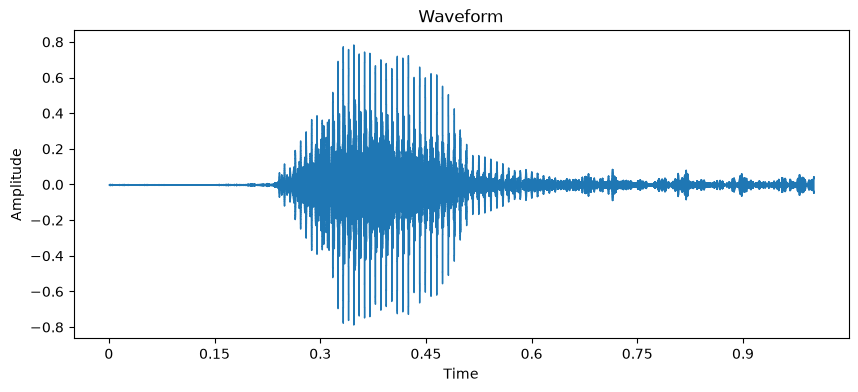

Mean: 1.7812339137890376e-05, Median: 0.00040914781857281923, Variance: 0.008622154593467712


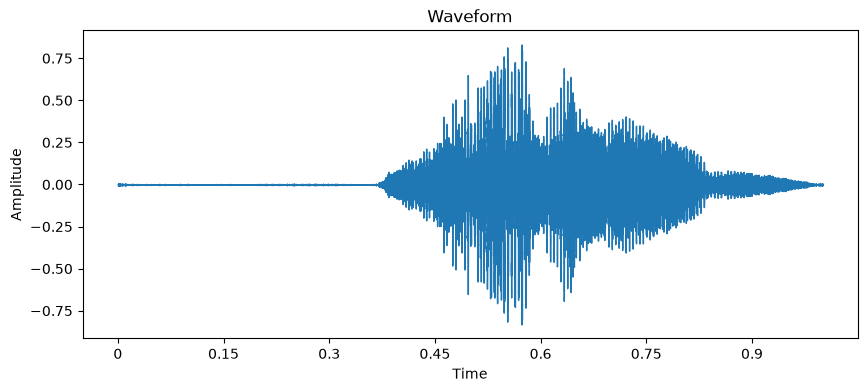

Mean: 6.048574869055301e-05, Median: 5.828906432725489e-05, Variance: 0.014457154087722301


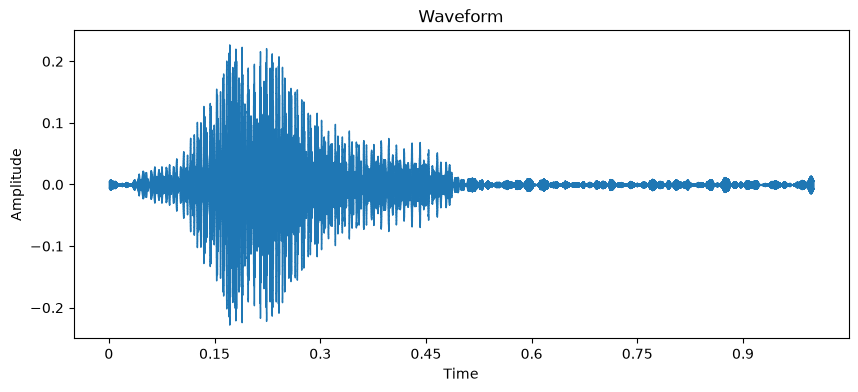

Mean: -8.249750680988654e-05, Median: 0.0007470747223123908, Variance: 0.0014567469479516149


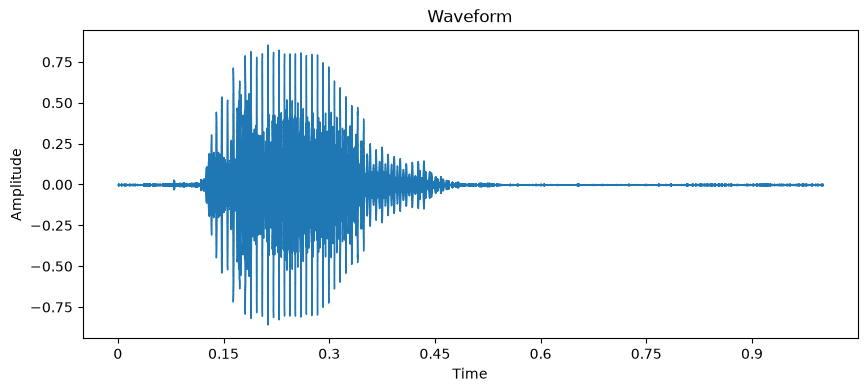

Mean: 1.0973471944453195e-05, Median: -0.0004533413448370993, Variance: 0.01739867404103279


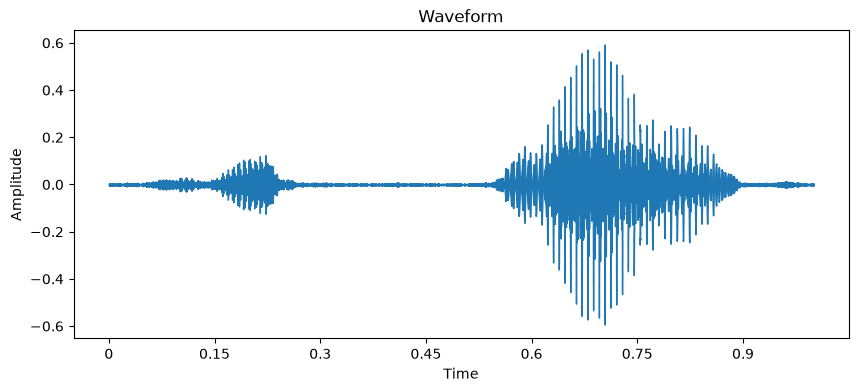

Mean: 8.492547931382433e-05, Median: 0.0005053004715591669, Variance: 0.004348552320152521


In [4]:
listado_muestra= ["data/train/one/b97c9f77_nohash_2.wav",
"data/train/one/c948d727_nohash_3.wav",
"data/train/one/05cf43ef_nohash_0.wav",
"data/train/one/5b09db89_nohash_1.wav",
"data/train/one/8134f43f_nohash_1.wav"]

for muestra in listado_muestra:
    y, sr = librosa.load(muestra)
    plt.figure(figsize=(10, 4))
    librosa.display.waveshow(y, sr=sr)
    plt.title('Waveform')
    plt.xlabel('Time')
    plt.ylabel('Amplitude')
    plt.show()
    mean = np.mean(y)
    median = np.median(y)
    variance = np.var(y)
    print(f"Mean: {mean}, Median: {median}, Variance: {variance}")

## Preparación
Como son palabras vamos a utilizar algunas herramientas que se relacionan con los fonemas para ver que tal nos va, la idea es armar un dataset con los calculos obtenidos.
Utilizaremos las primeras tres formantes.

F1:  Indica la altura o abertura de la lengua. Es bajo en vocales cerradas como [i, u] y alto en vocales abiertas como [a].

F2:  Indica la posición anterior o posterior de la lengua. Ayuda a distinguir entre vocales palatales (frente) y velares (fondo).

F3:  Aporta matices sobre la forma de los labios y la naturalidad del sonido.

Tambien es muy utilizado:

MFCC: Coeficientes Cepstrales en las Frecuencias Mel, son parámetros que representan la envolvente espectral de una señal de audio y se usan de forma masiva en el reconocimiento de voz y procesamiento de sonido.

In [5]:
# FUNCION DE APOYO PARA GENERAR EL DATASET TABULAR
def generar_dataset_tabular(dir):
  datos = []
  for root, dirs, files in os.walk(dir):
    for file in files:
      # 1. Excluir todo lo que no sea .wav
      if not file.endswith(".wav"):
        continue

      ruta_completa = os.path.join(root, file)

      # 2. Obtener la palabra (nombre de la carpeta contenedora)
      word = os.path.basename(root)
      # excluyo background noise porque son audios mas largo
      if "_background_noise_" in word:
        continue

      if not word=='_unknown_':
        # 3. Parsear el nombre del archivo (ej: f19d1738_nohash_1.wav)
        nombre_base = file[:-4]  # Remueve '.wav'
        if "_nohash_" in nombre_base:
          person, take = nombre_base.split("_nohash_")
        else:
          # Plan de respaldo por si algún archivo tiene otro formato
          partes = nombre_base.split("_nohash_")
          person = partes[0]
          take = partes[-1]
      else: # caso especial de unknown de test
        nombre_base = file[:-8]
        if "_nohash_" in nombre_base:
          word, person, _ ,take = nombre_base.split("_")
        else:
          # Por si algún archivo tiene otro formato
          print("Error en otro formato de nombre")

      # Guardar los datos en una lista de diccionarios
      datos.append(
          {"person": person, "take": take, "word": word, "path": ruta_completa}
      )

  # 4. Crear el DataFrame
  df = pd.DataFrame(datos)
  # Ver los primeros resultados
  print(df.head())
  return df


In [6]:
df_train=generar_dataset_tabular(r"data/train")

     person take word                                  path
0  b97c9f77    2  one  data/train/one/b97c9f77_nohash_2.wav
1  c948d727    3  one  data/train/one/c948d727_nohash_3.wav
2  05cf43ef    0  one  data/train/one/05cf43ef_nohash_0.wav
3  5b09db89    1  one  data/train/one/5b09db89_nohash_1.wav
4  8134f43f    1  one  data/train/one/8134f43f_nohash_1.wav


In [7]:
len(df_train)

105829

In [8]:
df_test = generar_dataset_tabular(r"data/test")

     person take     word                                               path
0  af405b69    0      wow  data/test/_unknown_/wow_af405b69_nohash_0.wav.wav
1  bb05582b    0     zero  data/test/_unknown_/zero_bb05582b_nohash_0.wav...
2  4c6167ca    5  forward  data/test/_unknown_/forward_4c6167ca_nohash_5....
3  f9643d42    2  forward  data/test/_unknown_/forward_f9643d42_nohash_2....
4  91b03183    3    three  data/test/_unknown_/three_91b03183_nohash_3.wa...


In [9]:
len(df_test) # 5%

4890

In [10]:
train_speakers = set(df_train['person'])
test_speakers = set(df_test['person'])

overlap = train_speakers.intersection(test_speakers)

print(f"Hablantes repetidos (mezclados): {len(overlap)}")

Hablantes repetidos (mezclados): 239


In [11]:
# FUNCION DE APOYO PARA CALCULAR METRICAS DE MEL
# con GPU si esta disponible

def calcular_medidas(df,SR=16000):
  # 1. Configurar el dispositivo (CUDA)
  device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
  print(f"Calculando MFCCs en: {device}")

  # 2. Definir la transformación de MFCC en PyTorch y enviarla a la GPU
  mfcc_transform = torchaudio.transforms.MFCC(
      sample_rate=SR,
      n_mfcc=13,
      melkwargs={"n_fft": 400, "hop_length": 160, "n_mels": 23},
  ).to(device)

  mfcc_lists = []
  f1_list, f2_list, f3_list = [], [], []

  for ruta_completa in df["path"]:
    try:
      # A. Cargar el audio con Librosa (Evita por completo el error de TorchCodec)
      y, sr = librosa.load(ruta_completa, sr=16000)

      # Convertir el array a Tensor de PyTorch y enviarlo a la GPU (CUDA)
      waveform = torch.tensor(y, dtype=torch.float32).unsqueeze(0).to(device)

      # B. Calcular MFCCs directamente en la GPU
      mfccs = mfcc_transform(waveform)  # Forma: [1, n_mfcc, tiempo]
      mfccs_mean = mfccs.mean(dim=-1).squeeze(0).cpu().numpy()  # Promedio y vuelta a CPU
      mfcc_lists.append(mfccs_mean)

      # C. Cálculo de Formantes (F1, F2, F3) usando LPC en CPU
      y_preemph = librosa.effects.preemphasis(y)
      lpc_coeffs = librosa.lpc(y_preemph, order=int(sr / 2000 + 2))

      roots = np.roots(lpc_coeffs)
      roots = roots[np.imag(roots) > 0]
      ang = np.angle(roots)
      frequencies = sorted(ang * (sr / (2 * np.pi)))

      f1_list.append(frequencies[0] if len(frequencies) > 0 else np.nan)
      f2_list.append(frequencies[1] if len(frequencies) > 1 else np.nan)
      f3_list.append(frequencies[2] if len(frequencies) > 2 else np.nan)

    except Exception as e:
      print(f"Error procesando {ruta_completa}: {e}")
      mfcc_lists.append([np.nan] * 13)
      f1_list.append(np.nan)
      f2_list.append(np.nan)
      f3_list.append(np.nan)

  # 3. Integrar los resultados al DataFrame original
  df["F1"] = f1_list
  df["F2"] = f2_list
  df["F3"] = f3_list

  mfcc_df = pd.DataFrame(
      mfcc_lists, columns=[f"MFCC_{i}" for i in range(1, 14)]
  )
  df = pd.concat([df.reset_index(drop=True), mfcc_df], axis=1)

  print(df[["person", "word", "F1", "MFCC_1"]].head())
  return df

In [12]:
df_train = calcular_medidas(df_train)
df_test = calcular_medidas(df_test)

Calculando MFCCs en: cuda
     person word          F1      MFCC_1
0  b97c9f77  one  876.743225 -108.427750
1  c948d727  one  964.770569  -91.981880
2  05cf43ef  one  596.072571 -156.440674
3  5b09db89  one  646.626892 -116.872467
4  8134f43f  one  578.075989 -107.512894
Calculando MFCCs en: cuda
     person     word           F1      MFCC_1
0  af405b69      wow  1009.709534 -130.447906
1  bb05582b     zero   158.146027 -107.030243
2  4c6167ca  forward   594.538574 -138.177185
3  f9643d42  forward   813.085510 -149.260422
4  91b03183    three  1816.144165 -141.601135


In [13]:
# guardo el dataset calculado para evitar volver a calcular
ruta_df_train_calculado = f"data/train/dataset_con_metricas.csv"
df_train.to_csv(ruta_df_train_calculado, index=False)

ruta_df_test_calculado = f"data/test/dataset_con_metricas.csv"
df_test.to_csv(ruta_df_test_calculado, index=False)



In [14]:
# leer el dataset calculado para evitar volver a calcular
ruta_df_train_calculado = f"data/train/dataset_con_metricas.csv"
df_train = pd.read_csv(ruta_df_train_calculado)

ruta_df_test_calculado = f"data/test/dataset_con_metricas.csv"
df_test = pd.read_csv(ruta_df_test_calculado)

In [15]:
# FUNCION DE APOYO PARA VERIFICAR NULOS
def verificar_nulos(df):
    # 1. Contar cuántos NaN hay en total en todo el DataFrame
    total_nans = df.isna().sum().sum()
    print(f"Total de valores NaN en el DataFrame: {total_nans}")

    # 2. Ver cuántos NaN hay por cada columna (muestra solo las que tienen alguno)
    nans_por_columna = df.isna().sum()
    print("\nConteo de NaN por columna:")
    print(nans_por_columna[nans_por_columna > 0])

    # 3. Filtrar y ver cuáles filas (audios) tienen valores NaN
    filas_con_nans = df[df.isna().any(axis=1)]

In [16]:
verificar_nulos(df_train)

Total de valores NaN en el DataFrame: 2

Conteo de NaN por columna:
F3    2
dtype: int64


In [17]:
# COMO HAY NULOS Y POCOS ELIMINAMOS
# VAMOS A RESPETAR ESTA ELIMINACION
df_limpio = df_train.dropna().reset_index(drop=True)
df_train = df_limpio.copy()

In [18]:
verificar_nulos(df_test)

Total de valores NaN en el DataFrame: 0

Conteo de NaN por columna:
Series([], dtype: int64)


## Baseline Etapa 1

Ya con este dataset formado y caracteristicas calculadas probamos regression logistica

In [19]:

y_tr = df_train["word"]
columnas_a_excluir = ["person", "take", "word"] # el path lo conservamos hasta luego del split
X_tr = df_train.drop(columns=[col for col in columnas_a_excluir if col in df_train.columns])

y_te = df_test["word"]
X_te = df_test.drop(columns=[col for col in columnas_a_excluir if col in df_test.columns])

print(f"Tamaño total del dataset de train: {X_tr.shape} audios con {X_tr.shape[1]-1} características.") # restamos path

print(f"Tamaño total del dataset de test: {X_te.shape} audios con {X_te.shape[1]-1} características.") # restamos path

Tamaño total del dataset de train: (105827, 17) audios con 16 características.
Tamaño total del dataset de test: (4890, 17) audios con 16 características.


In [20]:
# 1. Partición de Datos (Estrategia Train / Dev / Test)
# Primero separamos el Train (80%) del resto (20%)
# Los datos finales de test separados ya en la descarga del dataset representan un 5% del train
X_train, X_dev, y_train, y_dev = train_test_split(X_tr, y_tr, test_size=0.20, random_state=42, stratify=y_tr) #separamos asi para poder tener el mismo conjunto
X_test, y_test = X_te, y_te
# para la etapa 2 que se planteó en clase de audio (espectrograma)
X_train_path=X_train.pop('path') # conservamos y quitamos el path de X
X_dev_path=X_dev.pop('path')
X_test_path=X_test.pop('path')


# 2. Escalar los datos (fundamental para que converjan los coeficientes de audio)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_dev_scaled = scaler.transform(X_dev)
X_test_scaled = scaler.transform(X_test)
print(f"Datos de Entrenamiento (Train): {X_train.shape}")
print(f"Datos de Desarrollo (Dev): {X_dev.shape}")
print(f"Datos de Entrenamiento (Test): {X_test.shape}")

Datos de Entrenamiento (Train): (84661, 16)
Datos de Desarrollo (Dev): (21166, 16)
Datos de Entrenamiento (Test): (4890, 16)


In [21]:
X_train.keys()

Index(['F1', 'F2', 'F3', 'MFCC_1', 'MFCC_2', 'MFCC_3', 'MFCC_4', 'MFCC_5',
       'MFCC_6', 'MFCC_7', 'MFCC_8', 'MFCC_9', 'MFCC_10', 'MFCC_11', 'MFCC_12',
       'MFCC_13'],
      dtype='str')

In [22]:
# 3. Construcción del Modelo Base (Baseline)
modelo_base = LogisticRegression(C=1, max_iter=200, verbose=1)
modelo_base.fit(X_train_scaled, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",200
,"verbose verbose: int, default=0For the liblinear and lbfgs solvers set verbose to any positivenumber for verbosity.",1
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None


In [23]:
def evaluate(modelo, X_dev, y_dev, X_te, y_te):
    # Realizar predicciones usando el conjunto de desarrollo/prueba escalado
    y_pred_dev = modelo.predict(X_dev)
    y_pred_test = modelo.predict(X_te)

    # Cálculos de Métricas (usando average='weighted' por ser multiclase)
    exactitud_dev = accuracy_score(y_dev, y_pred_dev)
    exactitud_test = accuracy_score(y_te, y_pred_test)
    precision_dev = precision_score(y_dev, y_pred_dev, average="weighted")
    precision_test = precision_score(y_te, y_pred_test, average="weighted")
    recall_dev = recall_score(y_dev, y_pred_dev, average="weighted")
    recall_test = recall_score(y_te, y_pred_test, average="weighted")
    f1_dev = f1_score(
    y_dev, y_pred_dev, average="weighted"
    )  # Nuestra métrica de número único
    f1_test = f1_score(
        y_te, y_pred_test, average="weighted"
        )  # Nuestra métrica de número único
    
    print("\n--- RESULTADOS EN EL CONJUNTO DEV ---")
    print(f"Exactitud (Accuracy): {exactitud_dev:.4f}")
    print(f"Precisión:            {precision_dev:.4f}")
    print(f"Exhaustividad (Recall):{recall_dev:.4f}")
    print(f"Puntaje F1 (F1-Score): {f1_dev:.4f}  <-- Métrica de número único")
    print("\n--- RESULTADOS EN EL CONJUNTO TEST ---")
    print(f"Exactitud (Accuracy): {exactitud_test:.4f}")
    print(f"Precisión:            {precision_test:.4f}")
    print(f"Exhaustividad (Recall):{recall_test:.4f}")
    print(f"Puntaje F1 (F1-Score): {f1_test:.4f}  <-- Métrica de número único")


In [24]:
evaluate(modelo_base, X_dev_scaled, y_dev, X_test_scaled, y_test)



--- RESULTADOS EN EL CONJUNTO DEV ---
Exactitud (Accuracy): 0.2599
Precisión:            0.2510
Exhaustividad (Recall):0.2599
Puntaje F1 (F1-Score): 0.2504  <-- Métrica de número único

--- RESULTADOS EN EL CONJUNTO TEST ---
Exactitud (Accuracy): 0.2108
Precisión:            0.3343
Exhaustividad (Recall):0.2108
Puntaje F1 (F1-Score): 0.2408  <-- Métrica de número único


/home/juan/miniconda3/envs/speech_cmd/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [25]:
from sklearn.linear_model import LogisticRegressionCV

# Busca el mejor 'C' entre una lista de opciones usando validación cruzada (cv=5)
modelo_cv = LogisticRegressionCV(
    Cs=[0.001, 0.01, 0.1, 1, 10, 100],
    cv=5,
    penalty="l2",
    solver="lbfgs",
    max_iter=300,
    random_state=42,
)

# Entrenar el modelo optimizado
modelo_cv.fit(X_train_scaled, y_train)

# Ver cuál fue el mejor valor de C que eligió automáticamente
print(f"Mejor valor de C encontrado: {modelo_cv.C_[0]}")
print(f"Precisión con el mejor C: {modelo_cv.score(X_dev_scaled, y_dev):.4f}")

/home/juan/miniconda3/envs/speech_cmd/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/juan/miniconda3/envs/speech_cmd/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:2102: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratios' and 'Cs' instead. Use l1_ratios=(0,) instead of penalty='l2', l1_ratios=(1,) instead of penalty='l1', l1_ratios set to floats between 0 and 1 instead of penalty='elasticnet', and Cs=(np.inf,) instead of penalty=None.
  warnings.warn(
/home/juan/miniconda3/envs/speech_cmd/lib/python3.11/site-packages/sklearn/linear_model/_logistic

Mejor valor de C encontrado: 1.0
Precisión con el mejor C: 0.2598


No mejora demasiado vamos a ir por otro intento sumando algunos coeficientes para ver de capturar los cambios en fonemas compuestos.

Agregando la desviacion estandar en los coeficientes de mel y tambien deltas (derivadas temporales de primer y segundo orden)

In [26]:
# FUNCION DE APOYO PARA CALCULO DE METRICAS EXTENDIDAS
def calcular_medidas_extendidas(df,SR=16000):
  # Forzar backend de sonido si es necesario
  try:
    torchaudio.set_audio_backend("soundfile")
  except:
    pass

  device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
  print(f"Procesando características avanzadas en: {device}")

  # Transformaciones en PyTorch/TorchAudio
  mfcc_transform = torchaudio.transforms.MFCC(
      sample_rate=SR,
      n_mfcc=13,
      melkwargs={"n_fft": 400, "hop_length": 160, "n_mels": 23},
  ).to(device)

  delta_transform = torchaudio.transforms.ComputeDeltas().to(device)

  datos_procesados = []

  for ruta_completa in df["path"]:
    try:
      # 1. Cargar audio con Librosa y enviar a PyTorch/CUDA
      y, sr = librosa.load(ruta_completa, sr=16000)
      waveform = torch.tensor(y, dtype=torch.float32).unsqueeze(0).to(device)

      # 2. Calcular MFCCs [1, 13, tiempo]
      mfccs = mfcc_transform(waveform)

      # 3. Calcular Deltas (velocidad) y Delta-Deltas (aceleración) de los MFCCs
      mfccs_delta = delta_transform(mfccs)
      mfccs_delta2 = delta_transform(mfccs_delta)

      # 4. Extraer estadísticas temporales para cada uno (Media y Desviación Estándar)
      # Esto resume la dinámica temporal en un vector fijo por cada audio
      mfcc_mean = mfccs.mean(dim=-1).squeeze(0).cpu().numpy()
      mfcc_std = mfccs.std(dim=-1).squeeze(0).cpu().numpy()

      delta_mean = mfccs_delta.mean(dim=-1).squeeze(0).cpu().numpy()
      delta_std = mfccs_delta.std(dim=-1).squeeze(0).cpu().numpy()

      delta2_mean = mfccs_delta2.mean(dim=-1).squeeze(0).cpu().numpy()
      delta2_std = mfccs_delta2.std(dim=-1).squeeze(0).cpu().numpy()

      # 5. Cálculo de Formantes (F1, F2, F3) usando LPC en CPU
      y_preemph = librosa.effects.preemphasis(y)
      lpc_coeffs = librosa.lpc(y_preemph, order=int(sr / 2000 + 2))
      roots = np.roots(lpc_coeffs)
      roots = roots[np.imag(roots) > 0]
      ang = np.angle(roots)
      frequencies = sorted(ang * (sr / (2 * np.pi)))

      f1 = frequencies[0] if len(frequencies) > 0 else np.nan
      f2 = frequencies[1] if len(frequencies) > 1 else np.nan
      f3 = frequencies[2] if len(frequencies) > 2 else np.nan

      # Estructura base de la fila con metadatos y formantes
      fila = {
          "person": df.loc[df["path"] == ruta_completa, "person"].values[0],
          "take": df.loc[df["path"] == ruta_completa, "take"].values[0],
          "word": df.loc[df["path"] == ruta_completa, "word"].values[0],
          "F1": f1,
          "F2": f2,
          "F3": f3,
      }

      # Agregar dinámicamente las columnas al diccionario
      for i in range(13):
        fila[f"MFCC_{i+1}_mean"] = mfcc_mean[i]
        fila[f"MFCC_{i+1}_std"] = mfcc_std[i]
        fila[f"Delta_{i+1}_mean"] = delta_mean[i]
        fila[f"Delta_{i+1}_std"] = delta_std[i]
        fila[f"Delta2_{i+1}_mean"] = delta2_mean[i]
        fila[f"Delta2_{i+1}_std"] = delta2_std[i]

      fila["path"] = ruta_completa
      datos_procesados.append(fila)

    except Exception as e:
      print(f"Error procesando {ruta_completa}: {e}")

  # Reconstruir el DataFrame completo con las nuevas características enriquecidas
  df_enriquecido = pd.DataFrame(datos_procesados)
  return df_enriquecido



In [27]:
df_train = calcular_medidas_extendidas(df_train)
df_test = calcular_medidas_extendidas(df_test)

Procesando características avanzadas en: cuda
Procesando características avanzadas en: cuda


In [28]:

# guardo el dataset calculado para evitar volver a calcular
ruta_df_train_ext_calculado = f"data/train/dataset_con_metricas_std+deltas.csv"
df_train.to_csv(ruta_df_train_ext_calculado, index=False)
ruta_df_test_ext_calculado = f"data/test/dataset_con_metricas_std+deltas.csv"
df_test.to_csv(ruta_df_test_ext_calculado, index=False)

In [29]:

# leer el dataset calculado para evitar volver a calcular
ruta_df_train_ext_calculado = f"data/train/dataset_con_metricas_std+deltas.csv"
df_train = pd.read_csv(ruta_df_train_ext_calculado)
ruta_df_test_ext_calculado = f"data/test/dataset_con_metricas_std+deltas.csv"
df_test = pd.read_csv(ruta_df_test_ext_calculado)


In [30]:
verificar_nulos(df_train)

Total de valores NaN en el DataFrame: 0

Conteo de NaN por columna:
Series([], dtype: int64)


In [31]:
verificar_nulos(df_test)

Total de valores NaN en el DataFrame: 0

Conteo de NaN por columna:
Series([], dtype: int64)


In [32]:
# Reemplazar el antiguo df por el enriquecido
X_train = pd.merge(X_train_path.copy(), df_train, on="path", how="left")
X_dev = pd.merge(X_dev_path.copy(), df_train, on="path", how="left")


In [33]:

columnas_a_excluir = ["person", "take", "word","path"]
X_train = X_train.copy().drop(columns=[col for col in columnas_a_excluir if col in df_train.columns])
X_dev = X_dev.copy().drop(columns=[col for col in columnas_a_excluir if col in df_train.columns])
X_test = df_test.copy().drop(columns=[col for col in columnas_a_excluir if col in df_test.columns])

# 2. Escalar los datos (fundamental para que converjan los coeficientes de audio)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_dev_scaled = scaler.transform(X_dev)
X_test_scaled = scaler.transform(X_test)
print(f"Datos de Entrenamiento (Train): {X_train.shape}")
print(f"Datos de Desarrollo (Dev): {X_dev.shape}")
print(f"Datos de Entrenamiento (Test): {X_test.shape}")



Datos de Entrenamiento (Train): (84661, 81)
Datos de Desarrollo (Dev): (21166, 81)
Datos de Entrenamiento (Test): (4890, 81)


In [34]:
# 3. Construcción del Modelo Base (Baseline)
modelo_base = LogisticRegression(C=1, max_iter=200, verbose=1)
modelo_base.fit(X_train_scaled, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",200
,"verbose verbose: int, default=0For the liblinear and lbfgs solvers set verbose to any positivenumber for verbosity.",1
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None


In [35]:
evaluate(modelo_base, X_dev_scaled, y_dev, X_test_scaled, y_test)



--- RESULTADOS EN EL CONJUNTO DEV ---
Exactitud (Accuracy): 0.5761
Precisión:            0.5741
Exhaustividad (Recall):0.5761
Puntaje F1 (F1-Score): 0.5743  <-- Métrica de número único

--- RESULTADOS EN EL CONJUNTO TEST ---
Exactitud (Accuracy): 0.5018
Precisión:            0.5840
Exhaustividad (Recall):0.5018
Puntaje F1 (F1-Score): 0.5223  <-- Métrica de número único


/home/juan/miniconda3/envs/speech_cmd/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [36]:
# Busca el mejor 'C' entre una lista de opciones usando validación cruzada (cv=5)
modelo_cv = LogisticRegressionCV(
    Cs=[0.001, 0.01, 0.1, 1, 10, 100],
    cv=5,
    penalty="l2",
    solver="lbfgs",
    max_iter=300,
    random_state=42,
)

# Entrenar el modelo optimizado
modelo_cv.fit(X_train_scaled, y_train)

# Ver cuál fue el mejor valor de C que eligió automáticamente
print(f"Mejor valor de C encontrado: {modelo_cv.C_[0]}")
print(f"Precisión con el mejor C: {modelo_cv.score(X_dev_scaled, y_dev):.4f}")

/home/juan/miniconda3/envs/speech_cmd/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/juan/miniconda3/envs/speech_cmd/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:2102: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratios' and 'Cs' instead. Use l1_ratios=(0,) instead of penalty='l2', l1_ratios=(1,) instead of penalty='l1', l1_ratios set to floats between 0 and 1 instead of penalty='elasticnet', and Cs=(np.inf,) instead of penalty=None.
  warnings.warn(
/home/juan/miniconda3/envs/speech_cmd/lib/python3.11/site-packages/sklearn/linear_model/_logistic

Mejor valor de C encontrado: 100.0
Precisión con el mejor C: 0.5756



# De la señal al espectrograma

In [37]:
def leer_audio(path):
    audio_bin = tf.io.read_file(path)
    waveform, sr = tf.audio.decode_wav(audio_bin, desired_channels=1)
    return waveform.numpy()[:, 0], int(sr.numpy())

labels, speakers, waves, rates = [], [], [], []
listado_audios = pd.concat([X_train_path,X_dev_path,X_test_path], axis=0, ignore_index=True)
for f in listado_audios:
    w, sr = leer_audio(f)
    waves.append(w)
    rates.append(sr)


print("Frecuencias de muestreo encontradas:", set(rates))
print(f"Duración promedio: {np.mean([len(w) for w in waves]) / rates[0]:.3f} s")

W0000 00:00:1793987684.680427 2508824 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
I0000 00:00:1793987684.683581 2508824 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 2554 MB memory:  -> device: 0, name: NVIDIA GeForce GTX 1650, pci bus id: 0000:01:00.0, compute capability: 7.5


Frecuencias de muestreo encontradas: {16000}
Duración promedio: 0.982 s


In [38]:
SR = 16000 # aca mantenemos 16000 porque en el baseline usamos ese sample_rate
N_MAX = SR  # clips de 1 segundo
FRAME_LENGTH = 512 # ventana de 32 ms en 16Khz
FRAME_STEP = 246  # salto de 16 ms en 16Khz
batch_size = 128

def ajustar_largo(w, n=N_MAX):
    w = w[:n]
    return np.pad(w, (0, n - len(w)))

def extraer_espectrograma(waves_batch):
    stft = tf.signal.stft(
        waves_batch,
        frame_length=FRAME_LENGTH,
        frame_step=FRAME_STEP,
        fft_length=FRAME_LENGTH,
    )
    return tf.math.log(tf.abs(stft) + 1e-6)[..., tf.newaxis].numpy()

# --- Procesamiento y Escritura Directa a Disco ---

#FUNCION DE GENERACION DE ESPECTROGRAMAS

def generar_espectrogramas(listado_rutas, ruta_salida):
    with h5py.File(ruta_salida, "w") as hf:
        dataset_x = None  # Lo inicializaremos con el primer lote

        for i in range(0, len(listado_rutas), batch_size):
            lote_rutas = listado_rutas[i:i + batch_size]
            waves_batch = []

            # 1. Cargar y procesar audios del lote
            for ruta in lote_rutas:
                w_orig, sr_orig = librosa.load(ruta, sr=None)
                if sr_orig != SR:
                    w_orig = librosa.resample(w_orig, orig_sr=sr_orig, target_sr=SR)
                waves_batch.append(ajustar_largo(w_orig))

            X_wave_lote = np.stack(waves_batch).astype(np.float32)
            spec_lote = extraer_espectrograma(X_wave_lote)

            # 2. Guardar en el HDF5
            if dataset_x is None:
                # Si es el primer lote, creamos el "molde" en el archivo
                forma_base = spec_lote.shape[1:]  # (tiempo, frecuencia, canal)
                # maxshape con 'None' permite que el dataset crezca infinitamente hacia abajo
                dataset_x = hf.create_dataset("X_spec", shape=(0, *forma_base),
                                            maxshape=(None, *forma_base),
                                            dtype='float32', compression="gzip")

            # Agrandamos el archivo en disco para que entre el nuevo lote
            dataset_x.resize(dataset_x.shape[0] + spec_lote.shape[0], axis=0)
            # Pegamos los datos del lote en las nuevas filas generadas
            dataset_x[-spec_lote.shape[0]:] = spec_lote

            print(f"Procesados y guardados: {dataset_x.shape[0]} / {len(listado_rutas)}")

        # 3. Guardar las rutas para auditar que el orden coincide con las etiquetas
        hf.create_dataset(
            "paths",
            data=np.asarray([str(ruta) for ruta in listado_rutas], dtype=h5py.string_dtype()),
        )

    print(f"Guardado {ruta_salida}: {len(listado_rutas)} espectrogramas")

#TRAIN
generar_espectrogramas(X_train_path, r"data/X_train_spec.h5")
# DEV
generar_espectrogramas(X_dev_path, r"data/X_dev_spec.h5")
# TEST
generar_espectrogramas(X_test_path, r"data/X_test_spec.h5")


Procesados y guardados: 128 / 84661
Procesados y guardados: 256 / 84661
Procesados y guardados: 384 / 84661
Procesados y guardados: 512 / 84661
Procesados y guardados: 640 / 84661
Procesados y guardados: 768 / 84661
Procesados y guardados: 896 / 84661
Procesados y guardados: 1024 / 84661
Procesados y guardados: 1152 / 84661
Procesados y guardados: 1280 / 84661
Procesados y guardados: 1408 / 84661
Procesados y guardados: 1536 / 84661
Procesados y guardados: 1664 / 84661
Procesados y guardados: 1792 / 84661
Procesados y guardados: 1920 / 84661
Procesados y guardados: 2048 / 84661
Procesados y guardados: 2176 / 84661
Procesados y guardados: 2304 / 84661
Procesados y guardados: 2432 / 84661
Procesados y guardados: 2560 / 84661
Procesados y guardados: 2688 / 84661
Procesados y guardados: 2816 / 84661
Procesados y guardados: 2944 / 84661
Procesados y guardados: 3072 / 84661
Procesados y guardados: 3200 / 84661
Procesados y guardados: 3328 / 84661
Procesados y guardados: 3456 / 84661
Procesad

In [39]:
df_test.value_counts('word')

word
up           425
yes          419
left         412
stop         411
_silence_    408
down         406
no           405
go           402
off          402
right        396
on           396
eight         34
six           28
three         26
one           25
zero          24
nine          24
five          23
happy         21
two           20
seven         18
four          18
sheila        17
wow           15
forward       13
marvin        11
bed           10
tree          10
cat           10
house         10
bird          10
learn         10
backward       9
follow         9
dog            7
visual         6
Name: count, dtype: int64

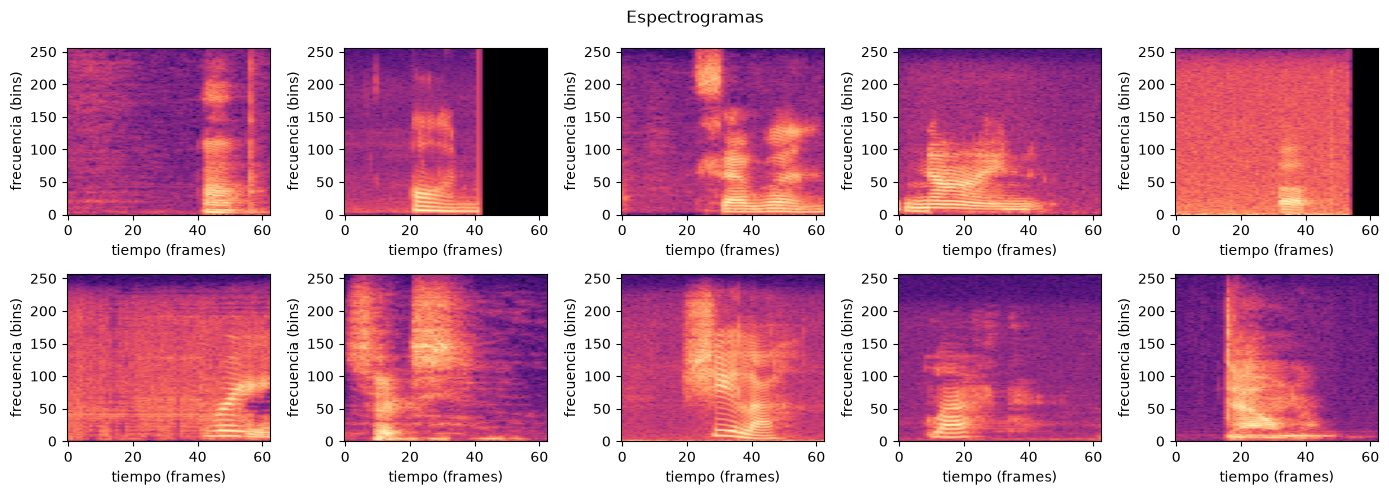

In [40]:
# 1. Abrimos el archivo en modo lectura ("r")
with h5py.File(r"data/X_train_spec.h5", "r") as hf:
    
    # Referencia al archivo en el disco
    X_disco = hf["X_spec"]
    
    # Extraemos solo los primeros 10 espectrogramas a la memoria RAM
    X_spec_lote = X_disco[0:10]

# 2. Tu código exacto, pero usando el lote que acabamos de extraer
fig, axes = plt.subplots(2, 5, figsize=(14, 5))
for d, ax in enumerate(axes.ravel()):
    i = d
    # Usamos X_spec_lote en lugar de cargar todo el dataset original
    ax.imshow(X_spec_lote[i, :, :, 0].T, origin="lower", aspect="auto", cmap="magma")
    # ax.set_title(f"Muestra {d}")
    ax.set_xlabel("tiempo (frames)")
    ax.set_ylabel("frecuencia (bins)")

plt.suptitle("Espectrogramas")
plt.tight_layout()
plt.show()

In [41]:
# A. Codificar etiquetas unificando el vocabulario para evitar errores (como _silence_)
le = LabelEncoder()
todas_las_etiquetas = pd.concat([y_train, y_dev, df_test['word']])
le.fit(todas_las_etiquetas)

y_tr_num = le.transform(y_train)
y_va_num = le.transform(y_dev)
y_te_num = le.transform(y_test)
print("Clases totales detectadas:", len(le.classes_))

num_classes=len(le.classes_)

# B. Calcular media y std SOLO de Train, por lotes para no cargar todo en RAM
def calcular_media_std_hdf5(h5_path, por_lote=256):
    suma = 0.0
    suma_cuadrados = 0.0
    cantidad = 0
    with h5py.File(h5_path, "r") as hf:
        dset = hf["X_spec"]
        forma = dset.shape[1:]
        for i in range(0, dset.shape[0], por_lote):
            lote = dset[i:i + por_lote].astype(np.float64)
            suma += lote.sum()
            suma_cuadrados += np.square(lote).sum()
            cantidad += lote.size
    mu = suma / cantidad
    varianza = max(suma_cuadrados / cantidad - mu ** 2, 0.0)
    return mu, float(np.sqrt(varianza)), forma

print("Calculando media y std de Train por lotes...")
mu, sd, INPUT_SHAPE = calcular_media_std_hdf5(r"data/X_train_spec.h5")
print(f"Media: {mu:.4f} | Std: {sd:.4f}")
print("Forma de entrada:", INPUT_SHAPE)


Clases totales detectadas: 36
Calculando media y std de Train por lotes...


Media: -5.1500 | Std: 2.7855
Forma de entrada: (63, 257, 1)


In [42]:
class GeneradorLotesHDF5(tf.keras.utils.Sequence):
    def __init__(self, h5_path, etiquetas, batch_size, mu, sd, shuffle=False, rutas_esperadas=None):
        super().__init__()
        self.h5_path = h5_path
        self.etiquetas = np.asarray(etiquetas)
        self.batch_size = batch_size
        self.mu = mu
        self.sd = sd
        self.shuffle = shuffle

        with h5py.File(self.h5_path, "r") as hf:
            self.num_samples = hf["X_spec"].shape[0]
            rutas_h5 = None
            if rutas_esperadas is not None:
                if "paths" not in hf:
                    raise ValueError(
                        f"{self.h5_path} no tiene el dataset 'paths'. "
                        "Regenerá los espectrogramas con la función actualizada."
                    )
                rutas_h5 = [p.decode() if isinstance(p, bytes) else str(p) for p in hf["paths"][:]]

        if len(self.etiquetas) != self.num_samples:
            raise ValueError(
                f"{self.h5_path}: hay {self.num_samples} espectrogramas pero "
                f"{len(self.etiquetas)} etiquetas. Regenerá el .h5 antes de entrenar."
            )

        if rutas_esperadas is not None:
            rutas_esperadas = [str(r) for r in rutas_esperadas]
            if rutas_h5 != rutas_esperadas:
                raise ValueError(
                    f"{self.h5_path}: el orden de las rutas del .h5 no coincide "
                    "con el de las etiquetas. Regenerá el .h5 antes de entrenar."
                )

        self.indices = np.arange(self.num_samples)

    def __len__(self):
        return int(np.ceil(self.num_samples / self.batch_size))

    def __getitem__(self, i):
        idx = self.indices[i * self.batch_size:(i + 1) * self.batch_size]

        # h5py exige índices ordenados; después reordenamos para respetar el shuffle
        idx_ordenados = np.sort(idx)
        posiciones = np.searchsorted(idx_ordenados, idx)

        # Lee SOLO el lote actual del disco
        with h5py.File(self.h5_path, "r") as hf:
            X_lote_crudo = hf["X_spec"][idx_ordenados][posiciones]

        # Normaliza este pequeño lote al vuelo
        X_norm = (X_lote_crudo - self.mu) / self.sd
        y_lote = self.etiquetas[idx]

        return X_norm, y_lote

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)

# Definir los parámetros
BATCH_SIZE = 32

# Instanciamos los generadores listos para usarse
train_gen = GeneradorLotesHDF5(r"data/X_train_spec.h5", y_tr_num, BATCH_SIZE, mu, sd,
                               shuffle=True, rutas_esperadas=X_train_path)
val_gen = GeneradorLotesHDF5(r"data/X_dev_spec.h5", y_va_num, BATCH_SIZE, mu, sd,
                             rutas_esperadas=X_dev_path)
test_gen = GeneradorLotesHDF5(r"data/X_test_spec.h5", y_te_num, BATCH_SIZE, mu, sd,
                              rutas_esperadas=X_test_path)


In [43]:
RESULTADOS = {}
MODELOS = {}

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"¡GPU detectada! TensorFlow usará: {gpus[0]}")
else:
    print("No se detectó GPU. TensorFlow usará la CPU.")

def entrenar_y_evaluar(nombre, modelo, train_gen, val_gen, test_gen, epochs=60, extra_callbacks=()):
    # Mantenemos el compilador igual
    modelo.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=3e-4),
                   loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    
    # Mantenemos el Early Stopping
    cbs = [callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
           *extra_callbacks]
    
    t0 = time.time()
    
    # Usamos los generadores en lugar de Xtr, ytr
    # Nota: validation_data acepta un generador directamente.
    # El batch_size ya lo define internamente el generador, así que lo quitamos de model.fit
    hist = modelo.fit(train_gen, 
                      validation_data=val_gen, 
                      epochs=epochs,
                      callbacks=cbs, 
                      verbose=2)
    
    seg = time.time() - t0
    
    # Evaluamos usando el generador de test
    acc = modelo.evaluate(test_gen, verbose=0)[1]
    
    # Guardamos los resultados
    RESULTADOS[nombre] = {"acc": acc, "params": modelo.count_params(),
                          "epocas": len(hist.history["loss"]), "seg": seg}
    MODELOS[nombre] = modelo
    
    print(f"{nombre}: exactitud test = {acc:.3f} | parámetros = {modelo.count_params():,} "
          f"| épocas = {len(hist.history['loss'])} | {seg:.0f} s")
    
    return hist

def graficar_historia(hist, titulo):
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
    ax[0].plot(hist.history["loss"], label="train")
    ax[0].plot(hist.history["val_loss"], label="validación")
    ax[0].set_title(f"{titulo}: pérdida"); ax[0].set_xlabel("época"); ax[0].legend()
    ax[1].plot(hist.history["accuracy"], label="train")
    ax[1].plot(hist.history["val_accuracy"], label="validación")
    ax[1].set_title(f"{titulo}: exactitud"); ax[1].set_xlabel("época"); ax[1].legend()
    plt.tight_layout(); plt.show()




¡GPU detectada! TensorFlow usará: PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')


In [44]:
def nivel0_mlp(input_shape):
    return models.Sequential([
        layers.Input(shape=input_shape),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dense(num_classes, activation="softmax"),
    ], name="N0_MLP")

m0 = nivel0_mlp(INPUT_SHAPE)
m0.summary()

Model: "N0_MLP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 16191)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     2,072,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 36)             │         4,644 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,077,220 (7.92 MB)

 Trainable params: 2,077,220 (7.92 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
h0 = entrenar_y_evaluar("N0 MLP", m0, train_gen, val_gen, test_gen)
graficar_historia(h0, "N0 MLP")

Epoch 1/60


I0000 00:00:1793990826.611445 2508824 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
I0000 00:00:1793990830.114397 2527597 service.cc:153] XLA service 0x7af930030560 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793990830.114431 2527597 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce GTX 1650, Compute Capability 7.5 (Driver: 13.0.0; Runtime: 13.0.0; Toolkit: 12.5.0; DNN: 9.24.0)
I0000 00:00:1793990832.412378 2527597 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1793990835.530802 2527597 cuda_dnn.cc:461] Loaded cuDNN version 92400
I0000 00:00:1793990836.510084 2527597 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_527030__.12
I0000 00:00:1793990840.110321 2527597 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
I0000

2646/2646 - 1962s - 741ms/step - accuracy: 0.2193 - loss: 2.9155 - val_accuracy: 0.3289 - val_loss: 2.4331
Epoch 2/60
2646/2646 - 1891s - 715ms/step - accuracy: 0.3737 - loss: 2.2553 - val_accuracy: 0.3985 - val_loss: 2.2023
Epoch 3/60


In [ ]:
def nivel1_cnn_minima(input_shape):
    return models.Sequential([
        layers.Input(shape=input_shape),
        layers.Conv2D(8, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(num_classes, activation="softmax"),
    ], name="N1_CNN_minima")

m1 = nivel1_cnn_minima(INPUT_SHAPE)
m1.summary()

Model: "N1_CNN_minima"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 63, 257, 8)     │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 128, 8)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 31744)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 36)             │     1,142,820 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,142,900 (4.36 MB)

 Trainable params: 1,142,900 (4.36 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/60


I0000 00:00:1793853810.661021 1196132 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_744349__.20
I0000 00:00:1793853832.024609 1196132 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_744349__.20


2646/2646 - 102s - 39ms/step - accuracy: 0.3501 - loss: 2.4350 - val_accuracy: 0.4273 - val_loss: 2.0935
Epoch 2/60
2646/2646 - 95s - 36ms/step - accuracy: 0.5307 - loss: 1.7733 - val_accuracy: 0.5133 - val_loss: 1.8233
Epoch 3/60
2646/2646 - 93s - 35ms/step - accuracy: 0.6294 - loss: 1.4247 - val_accuracy: 0.5172 - val_loss: 1.7745
Epoch 4/60
2646/2646 - 94s - 35ms/step - accuracy: 0.7103 - loss: 1.1301 - val_accuracy: 0.5221 - val_loss: 1.7594
Epoch 5/60
2646/2646 - 90s - 34ms/step - accuracy: 0.7789 - loss: 0.8857 - val_accuracy: 0.5013 - val_loss: 1.8407
Epoch 6/60
2646/2646 - 93s - 35ms/step - accuracy: 0.8357 - loss: 0.6816 - val_accuracy: 0.5108 - val_loss: 1.8520
Epoch 7/60
2646/2646 - 89s - 33ms/step - accuracy: 0.8800 - loss: 0.5179 - val_accuracy: 0.4909 - val_loss: 1.9701
Epoch 8/60
2646/2646 - 98s - 37ms/step - accuracy: 0.9170 - loss: 0.3853 - val_accuracy: 0.4831 - val_loss: 2.1085
Epoch 9/60
2646/2646 - 95s - 36ms/step - accuracy: 0.9424 - loss: 0.2836 - val_accuracy: 0

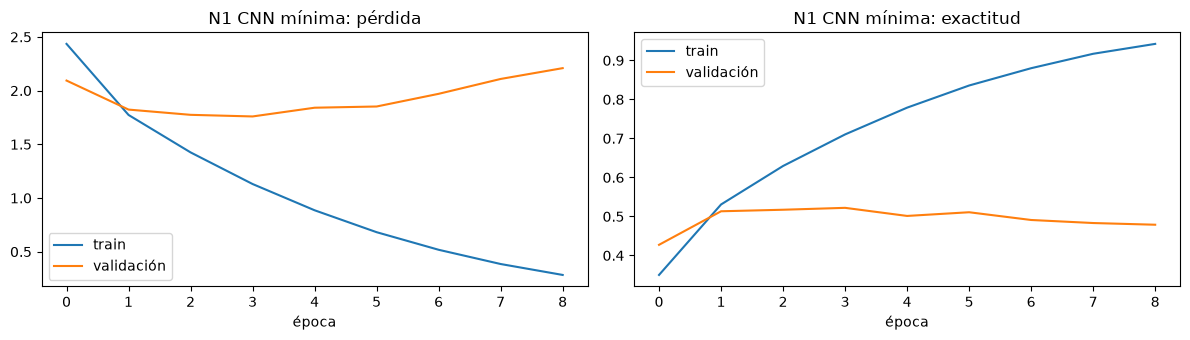

In [ ]:
h1 = entrenar_y_evaluar("N1 CNN mínima", m1, train_gen, val_gen, test_gen)
graficar_historia(h1, "N1 CNN mínima")

In [ ]:
def bloque_conv_2d(filtros):
    return [
        layers.Conv2D(filtros, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),
    ]

def nivel2_cnn(input_shape, cabezal="flatten"):
    capas = [layers.Input(shape=input_shape)]
    for f in (16, 32):
        capas += bloque_conv_2d(f)
    capas += [layers.Conv2D(64, (3, 3), activation="relu", padding="same")]
    if cabezal == "flatten":
        capas += [layers.MaxPooling2D((2, 2)), layers.Flatten()]
    else:
        capas += [layers.GlobalAveragePooling2D()]
    capas += [layers.Dense(64, activation="relu"),
              layers.Dropout(0.3),
              layers.Dense(num_classes, activation="softmax")]
    return models.Sequential(capas, name=f"N2_{cabezal}")

m2_flat = nivel2_cnn(INPUT_SHAPE, "flatten")

In [ ]:
h2_flat = entrenar_y_evaluar("N2 Flatten", m2_flat, train_gen, val_gen, test_gen)

Epoch 1/60


I0000 00:00:1793854666.698913 1196132 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_866543__.40
E0000 00:00:1793854668.684880 1196132 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1793854669.605566 1196132 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
I0000 00:00:1793854682.894993 1196131 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_866543__.40
E0000 00:00:1793854684.594436 1196131 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1793854685.126306 1196131 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup

2646/2646 - 114s - 43ms/step - accuracy: 0.2854 - loss: 2.5186 - val_accuracy: 0.6009 - val_loss: 1.4698
Epoch 2/60
2646/2646 - 94s - 36ms/step - accuracy: 0.5103 - loss: 1.6257 - val_accuracy: 0.7220 - val_loss: 1.0252
Epoch 3/60
2646/2646 - 96s - 36ms/step - accuracy: 0.5915 - loss: 1.3208 - val_accuracy: 0.7576 - val_loss: 0.8535
Epoch 4/60
2646/2646 - 90s - 34ms/step - accuracy: 0.6420 - loss: 1.1480 - val_accuracy: 0.7891 - val_loss: 0.7397
Epoch 5/60
2646/2646 - 93s - 35ms/step - accuracy: 0.6758 - loss: 1.0293 - val_accuracy: 0.7995 - val_loss: 0.6887
Epoch 6/60
2646/2646 - 88s - 33ms/step - accuracy: 0.7063 - loss: 0.9331 - val_accuracy: 0.8204 - val_loss: 0.6238
Epoch 7/60
2646/2646 - 86s - 33ms/step - accuracy: 0.7268 - loss: 0.8523 - val_accuracy: 0.8229 - val_loss: 0.6006
Epoch 8/60
2646/2646 - 94s - 35ms/step - accuracy: 0.7469 - loss: 0.7853 - val_accuracy: 0.8353 - val_loss: 0.5600
Epoch 9/60
2646/2646 - 93s - 35ms/step - accuracy: 0.7630 - loss: 0.7303 - val_accuracy: 0

In [ ]:
m2_gap = nivel2_cnn(INPUT_SHAPE, "gap")

In [ ]:
h2_gap = entrenar_y_evaluar("N2 GAP", m2_gap, train_gen, val_gen, test_gen)

Epoch 1/60


I0000 00:00:1793856269.605445 1196132 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1095140__.33
I0000 00:00:1793856303.862578 1196135 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1095140__.33


2646/2646 - 98s - 37ms/step - accuracy: 0.0728 - loss: 3.4047 - val_accuracy: 0.1210 - val_loss: 3.2283
Epoch 2/60
2646/2646 - 98s - 37ms/step - accuracy: 0.1287 - loss: 3.1359 - val_accuracy: 0.1762 - val_loss: 2.9575
Epoch 3/60
2646/2646 - 92s - 35ms/step - accuracy: 0.1756 - loss: 2.9162 - val_accuracy: 0.2116 - val_loss: 2.7746
Epoch 4/60
2646/2646 - 93s - 35ms/step - accuracy: 0.2120 - loss: 2.7513 - val_accuracy: 0.2672 - val_loss: 2.5826
Epoch 5/60
2646/2646 - 97s - 37ms/step - accuracy: 0.2456 - loss: 2.6250 - val_accuracy: 0.3098 - val_loss: 2.4490
Epoch 6/60
2646/2646 - 90s - 34ms/step - accuracy: 0.2759 - loss: 2.5088 - val_accuracy: 0.3294 - val_loss: 2.3637
Epoch 7/60
2646/2646 - 100s - 38ms/step - accuracy: 0.3017 - loss: 2.4114 - val_accuracy: 0.3572 - val_loss: 2.2670
Epoch 8/60
2646/2646 - 96s - 36ms/step - accuracy: 0.3213 - loss: 2.3293 - val_accuracy: 0.3851 - val_loss: 2.1379
Epoch 9/60
2646/2646 - 93s - 35ms/step - accuracy: 0.3419 - loss: 2.2514 - val_accuracy: 0

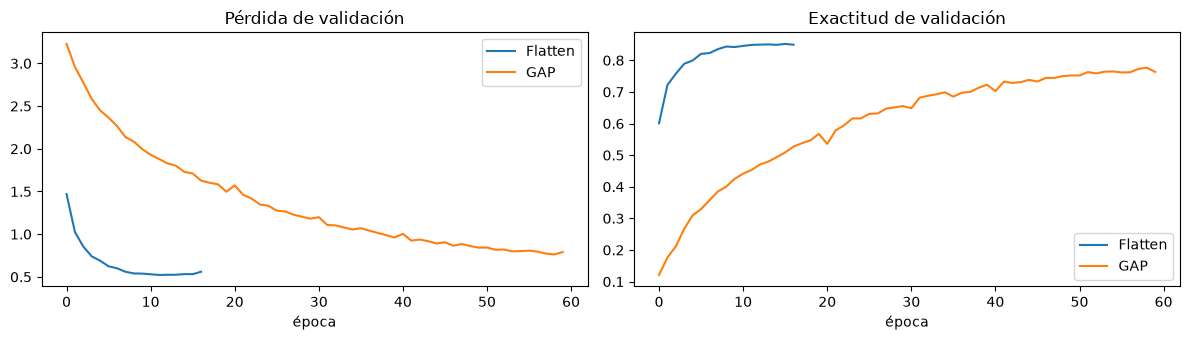

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for nombre, h in [("Flatten", h2_flat), ("GAP", h2_gap)]:
    ax[0].plot(h.history["val_loss"], label=nombre)
    ax[1].plot(h.history["val_accuracy"], label=nombre)
ax[0].set_title("Pérdida de validación"); ax[0].set_xlabel("época"); ax[0].legend()
ax[1].set_title("Exactitud de validación"); ax[1].set_xlabel("época"); ax[1].legend()
plt.tight_layout(); plt.show()

In [ ]:
def bloque_conv_bn(filtros):
    return [
        layers.Conv2D(filtros, (3, 3), padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D((2, 2)),
    ]

def nivel3_cnn_regularizada(input_shape):
    capas = [layers.Input(shape=input_shape)]
    for f in (16, 32, 64):
        capas += bloque_conv_bn(f)
    capas += [layers.Flatten(),
              layers.Dense(64, activation="relu"),
              layers.Dropout(0.4),
              layers.Dense(num_classes, activation="softmax")]
    return models.Sequential(capas, name="N3_CNN_regularizada")

m3 = nivel3_cnn_regularizada(INPUT_SHAPE)
m3.summary()
reduce_lr = callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, verbose=0)

Model: "N3_CNN_regularizada"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_7 (Conv2D)               │ (None, 63, 257, 16)    │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 63, 257, 16)    │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 63, 257, 16)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 31, 128, 16)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 31, 128, 32)    │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 31, 128, 32)    │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 31, 128, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 15, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 15, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 15, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 15, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 7, 32, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 14336)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │       917,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 36)             │         2,340 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 943,540 (3.60 MB)

 Trainable params: 943,316 (3.60 MB)

 Non-trainable params: 224 (896.00 B)

Epoch 1/60


I0000 00:00:1793861869.491707 1196132 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1895434__.55
I0000 00:00:1793861934.742307 1196133 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1895434__.55


2646/2646 - 107s - 40ms/step - accuracy: 0.0370 - loss: 3.5501 - val_accuracy: 0.0383 - val_loss: 3.5253 - learning_rate: 3.0000e-04
Epoch 2/60
2646/2646 - 94s - 36ms/step - accuracy: 0.0369 - loss: 3.5155 - val_accuracy: 0.0383 - val_loss: 3.5086 - learning_rate: 3.0000e-04
Epoch 3/60
2646/2646 - 96s - 36ms/step - accuracy: 0.0377 - loss: 3.5053 - val_accuracy: 0.0383 - val_loss: 3.5027 - learning_rate: 3.0000e-04
Epoch 4/60
2646/2646 - 91s - 35ms/step - accuracy: 0.0374 - loss: 3.5014 - val_accuracy: 0.0383 - val_loss: 3.5002 - learning_rate: 3.0000e-04
Epoch 5/60
2646/2646 - 90s - 34ms/step - accuracy: 0.0381 - loss: 3.4997 - val_accuracy: 0.0383 - val_loss: 3.4991 - learning_rate: 3.0000e-04
Epoch 6/60
2646/2646 - 97s - 37ms/step - accuracy: 0.0372 - loss: 3.4988 - val_accuracy: 0.0382 - val_loss: 3.4985 - learning_rate: 3.0000e-04
Epoch 7/60
2646/2646 - 92s - 35ms/step - accuracy: 0.0379 - loss: 3.4984 - val_accuracy: 0.0383 - val_loss: 3.4981 - learning_rate: 3.0000e-04
Epoch 8/6

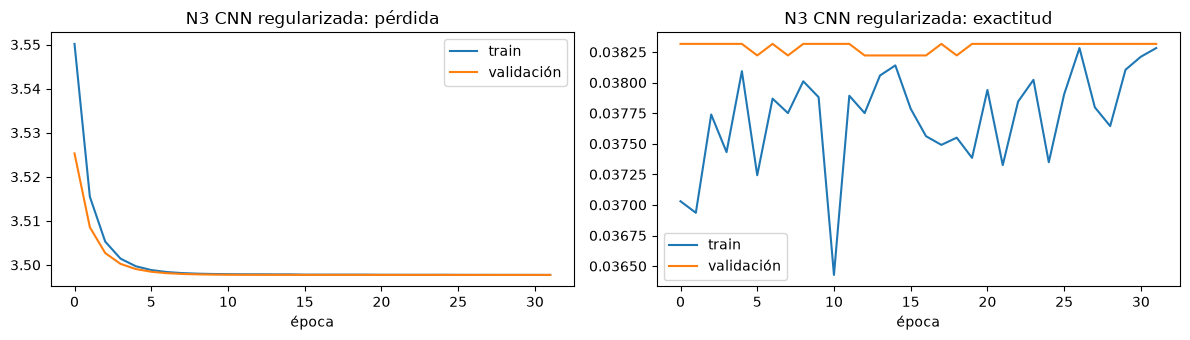

In [ ]:
h3 = entrenar_y_evaluar("N3 CNN regularizada", m3, train_gen, val_gen, test_gen,
                        extra_callbacks=[reduce_lr])
graficar_historia(h3, "N3 CNN regularizada")

In [ ]:
def nivel4_crnn(input_shape):
    T = input_shape[0] // 4   # tiempo después de dos pools de 2
    F = input_shape[1] // 4   # frecuencia después de dos pools de 2
    return models.Sequential([
        layers.Input(shape=input_shape),
        layers.Conv2D(16, (3, 3), padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(32, (3, 3), padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Reshape((T, F * 32)),   # secuencia de T pasos, cada uno con F*32 valores
        layers.GRU(64),
        layers.Dropout(0.3),
        layers.Dense(num_classes, activation="softmax"),
    ], name="N4_CRNN")

m4 = nivel4_crnn(INPUT_SHAPE)
m4.summary()

Model: "N4_CRNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_10 (Conv2D)              │ (None, 63, 257, 16)    │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 63, 257, 16)    │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 63, 257, 16)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 31, 128, 16)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 31, 128, 32)    │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 31, 128, 32)    │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 31, 128, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 15, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 15, 2048)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 64)             │       405,888 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 36)             │         2,340 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 413,172 (1.58 MB)

 Trainable params: 413,076 (1.58 MB)

 Non-trainable params: 96 (384.00 B)

Epoch 1/60


2646/2646 - 105s - 40ms/step - accuracy: 0.4907 - loss: 1.9176 - val_accuracy: 0.7627 - val_loss: 0.9336 - learning_rate: 3.0000e-04
Epoch 2/60
2646/2646 - 97s - 37ms/step - accuracy: 0.7751 - loss: 0.8307 - val_accuracy: 0.8440 - val_loss: 0.5899 - learning_rate: 3.0000e-04
Epoch 3/60
2646/2646 - 99s - 37ms/step - accuracy: 0.8360 - loss: 0.5960 - val_accuracy: 0.8623 - val_loss: 0.4952 - learning_rate: 3.0000e-04
Epoch 4/60
2646/2646 - 99s - 38ms/step - accuracy: 0.8622 - loss: 0.4855 - val_accuracy: 0.8900 - val_loss: 0.3917 - learning_rate: 3.0000e-04
Epoch 5/60
2646/2646 - 99s - 37ms/step - accuracy: 0.8824 - loss: 0.4137 - val_accuracy: 0.8969 - val_loss: 0.3554 - learning_rate: 3.0000e-04
Epoch 6/60
2646/2646 - 98s - 37ms/step - accuracy: 0.8955 - loss: 0.3665 - val_accuracy: 0.9020 - val_loss: 0.3358 - learning_rate: 3.0000e-04
Epoch 7/60
2646/2646 - 95s - 36ms/step - accuracy: 0.9065 - loss: 0.3252 - val_accuracy: 0.9096 - val_loss: 0.3134 - learning_rate: 3.0000e-04
Epoch 8/6

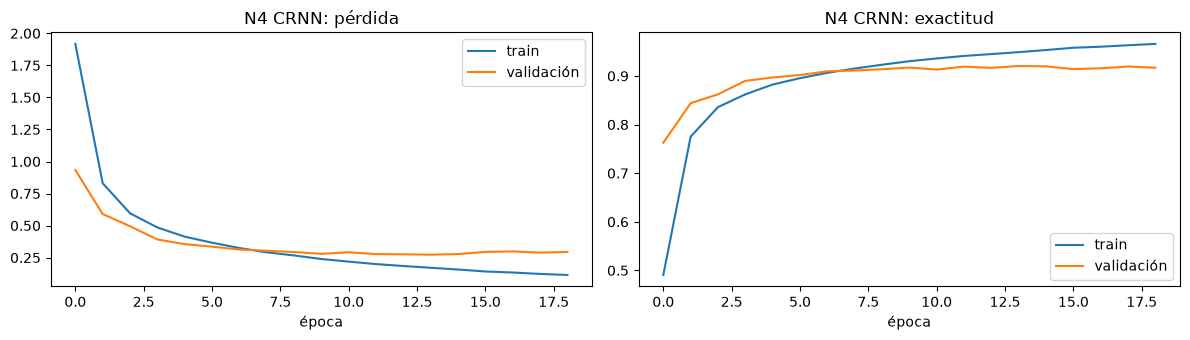

In [ ]:
h4 = entrenar_y_evaluar("N4 CRNN", m4, train_gen, val_gen, test_gen,
                        extra_callbacks=[reduce_lr])
graficar_historia(h4, "N4 CRNN")